## Topic is Healthy Food

**Will Mauro Ehsanul Kyle Project**



In [14]:
from pathlib import Path

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

data_path = Path("openfoodfacts.csv")

print("Working folder:", Path.cwd())
print("Dataset found:", data_path.exists())

headers = pd.read_csv(data_path, nrows=0)

print("Number of columns:", len(headers.columns))
print(headers.columns.tolist())

Working folder: c:\Users\willg\OneDrive\105 data expl\cmpsc105-project
Dataset found: True
Number of columns: 36
['Unnamed: 0', 'product_name', 'generic_name', 'quantity', 'brands', 'categories_en', 'origins_en', 'countries_en', 'traces_en', 'additives_n', 'additives_en', 'nutriscore_score', 'food_groups_en', 'ecoscore_score', 'ecoscore_grade', 'main_category_en', 'energy-kcal_100g', 'fat_100g', 'saturated-fat_100g', 'monounsaturated-fat_100g', 'polyunsaturated-fat_100g', 'trans-fat_100g', 'cholesterol_100g', 'carbohydrates_100g', 'sugars_100g', 'fiber_100g', 'proteins_100g', 'salt_100g', 'sodium_100g', 'vitamin-a_100g', 'vitamin-c_100g', 'potassium_100g', 'calcium_100g', 'iron_100g', 'fruits-vegetables-nuts-estimate-from-ingredients_100g', 'nutrition-score-fr_100g']


In [15]:
columns_to_use = [
    "product_name",
    "countries_en",
    "main_category_en",
    "energy-kcal_100g",
    "fat_100g",
    "saturated-fat_100g",
    "carbohydrates_100g",
    "sugars_100g",
    "fiber_100g",
    "proteins_100g",
    "salt_100g",
]

df = pd.read_csv(
    data_path,
    usecols=columns_to_use,
    low_memory=False,
)

print("Rows and columns:", df.shape)
display(df.head())

Rows and columns: (1982824, 11)


,product_name,countries_en,main_category_en,energy-kcal_100g,fat_100g,saturated-fat_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g
0,Skyr,France,Cream cheeses,57.00,0.20,0.10,3.90,3.90,NaN,10.00,0.09
1,Vitória crackers,France,NaN,375.00,7.00,3.08,70.10,15.00,NaN,7.80,1.40
2,Hamburguesas de ternera 100%,Spain,NaN,874.90,15.10,6.10,2.60,1.00,NaN,15.70,2.10
3,Blueberry Cobbler Coffee,United States,NaN,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
4,Sauce Sweety chili 0%,France,NaN,21.00,0.00,0.00,4.80,0.40,NaN,0.20,2.04


**Explanation**

We loaded 11 columns which include product names, countries, categories, as well as different nutritional measures. We used every row from the data and excluded the other columns. The nutrient columns are per 100 grams. 

In [16]:
df.info()

missing_before = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": df.isna().mean() * 100,
})

display(
    missing_before.sort_values(
        "missing_percent", ascending=False
    ).round(2)
)

<class 'pandas.DataFrame'>
RangeIndex: 1982824 entries, 0 to 1982823
Data columns (total 11 columns):
 #   Column              Dtype  
---  ------              -----  
 0   product_name        str    
 1   countries_en        str    
 2   main_category_en    str    
 3   energy-kcal_100g    float64
 4   fat_100g            float64
 5   saturated-fat_100g  float64
 6   carbohydrates_100g  float64
 7   sugars_100g         float64
 8   fiber_100g          float64
 9   proteins_100g       float64
 10  salt_100g           float64
dtypes: float64(8), str(3)
memory usage: 166.4 MB


,missing_count,missing_percent
fiber_100g,1058276,53.37
main_category_en,931045,46.96
product_name,0,0.00
countries_en,0,0.00
energy-kcal_100g,0,0.00
saturated-fat_100g,0,0.00
fat_100g,0,0.00
carbohydrates_100g,0,0.00
sugars_100g,0,0.00
proteins_100g,0,0.00


We did this to check the data to see if numbers were stored as numbers and text as text. Then we looked at the missing values for the columns where we found a substantial amount in fiber and main category.

In [17]:
text_columns = [
    "product_name",
    "countries_en",
    "main_category_en",
]

numeric_columns = [
    "energy-kcal_100g",
    "fat_100g",
    "saturated-fat_100g",
    "carbohydrates_100g",
    "sugars_100g",
    "fiber_100g",
    "proteins_100g",
    "salt_100g",
]

# Remove extra spaces and standardize blank text values.
for column in text_columns:
    df[column] = df[column].astype("string").str.strip()
    df[column] = df[column].replace("", pd.NA)

# Convert nutrition columns to numbers.
# Text that cannot be converted becomes a missing value.
for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# Keep records with missing labels by marking them as Unknown.
for column in text_columns:
    df[column] = df[column].fillna("Unknown")

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1982824 entries, 0 to 1982823
Data columns (total 11 columns):
 #   Column              Dtype  
---  ------              -----  
 0   product_name        string 
 1   countries_en        string 
 2   main_category_en    string 
 3   energy-kcal_100g    float64
 4   fat_100g            float64
 5   saturated-fat_100g  float64
 6   carbohydrates_100g  float64
 7   sugars_100g         float64
 8   fiber_100g          float64
 9   proteins_100g       float64
 10  salt_100g           float64
dtypes: float64(8), string(3)
memory usage: 166.4 MB


**Cleaning**

We cleaned the dataset (the columns we are using) to prepare for the analysis. We removed the extra spaces from text and put Unknown into the missing text values so we can still use them in the dataset. We then converted the nutrition columns to numeric values so theyu could be used for graphs and calculations for our analysis. We left missing nutrition values blank since putting in zeros could give incorrect results. 

In [18]:
gram_columns = [
    "fat_100g",
    "saturated-fat_100g",
    "carbohydrates_100g",
    "sugars_100g",
    "fiber_100g",
    "proteins_100g",
    "salt_100g",
]

invalid_counts = {}

for column in gram_columns:
    invalid = (df[column] < 0) | (df[column] > 100)
    invalid_counts[column] = invalid.sum()
    df.loc[invalid, column] = float("nan")

negative_energy = df["energy-kcal_100g"] < 0
invalid_counts["negative_energy"] = negative_energy.sum()
df.loc[negative_energy, "energy-kcal_100g"] = float("nan")

display(
    pd.Series(
        invalid_counts,
        name="Values replaced with missing"
    ).to_frame()
)

print(
    "Energy values above 900 kcal per 100 g:",
    (df["energy-kcal_100g"] > 900).sum()
)

,Values replaced with missing
fat_100g,92
saturated-fat_100g,37
carbohydrates_100g,210
sugars_100g,87
fiber_100g,24
proteins_100g,53
salt_100g,894
negative_energy,0


Energy values above 900 kcal per 100 g: 2872


We replaced the values above 100 or below 0 with missing values since they are out of the range. There were 2872 values above the 900 kcal per 100 grams.

In [19]:
summary = df[numeric_columns].agg(
    ["count", "mean", "median", "std", "min", "max"]
).T

pd.options.display.float_format = "{:.2f}".format
display(summary)

,count,mean,median,std,min,max
energy-kcal_100g,1982824.00,7161503918.96,268.00,10084311698114.61,0.00,14200000000000000.00
fat_100g,1982732.00,14.21,8.00,17.51,0.00,100.00
saturated-fat_100g,1982787.00,5.18,2.00,7.72,0.00,100.00
carbohydrates_100g,1982614.00,28.03,16.00,27.66,0.00,100.00
sugars_100g,1982737.00,12.50,3.40,18.84,0.00,100.00
fiber_100g,924524.00,3.21,1.60,5.70,0.00,100.00
proteins_100g,1982771.00,9.28,6.50,10.49,0.00,100.00
salt_100g,1981930.00,1.32,0.63,3.92,0.00,100.00


Here are our findings of the count, mean, median, std, min, and max. We will have to look more into the max as to why that is so big. 

In [20]:
print("Most common country labels:")
display(df["countries_en"].value_counts().head(10))

print("Most common main categories:")
display(df["main_category_en"].value_counts().head(10))

print("Missing nutrition values after cleaning:")
display(df[numeric_columns].isna().sum())

Most common country labels:


countries_en
France            642578
United States     464902
Spain             204178
Italy             146460
Germany            85780
United Kingdom     60312
Canada             59554
Belgium            45667
Switzerland        42187
Australia          19341
Name: count, dtype: Int64

Most common main categories:


main_category_en
Unknown            931045
Groceries           50301
Snacks              33125
Biscuits            17899
Cheeses             15859
Confectioneries     13006
Breads              11048
Frozen desserts     10074
Frozen foods         9100
Yogurts              8834
Name: count, dtype: Int64

Missing nutrition values after cleaning:


energy-kcal_100g            0
fat_100g                   92
saturated-fat_100g         37
carbohydrates_100g        210
sugars_100g                87
fiber_100g            1058300
proteins_100g              53
salt_100g                 894
dtype: int64

France is the most common country label, with 642,578 products, followed by the United States with 464,902. This uneven representation could affect comparisons between countries. The most common main category is “Unknown,” with 931,045 products, which limits comparisons between food categories. Groceries and snacks are the most common known categories. Fiber has the most missing nutrition values, with 1,058,300 missing entries. The other nutrition columns have relatively few missing values, and calories have none after cleaning.

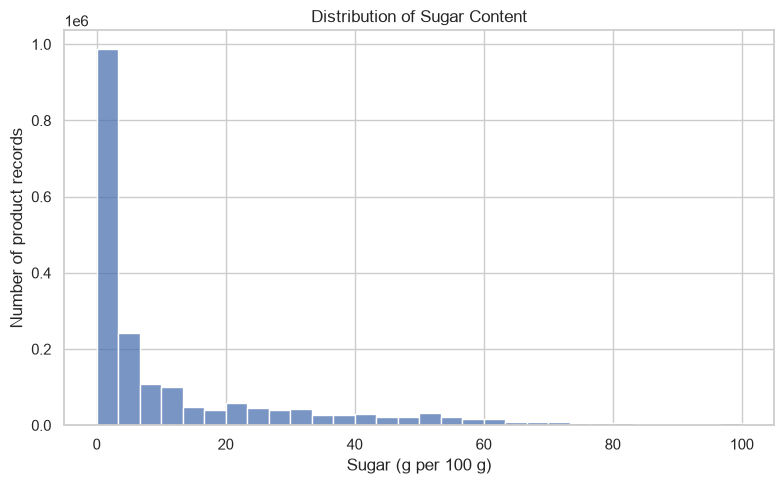

In [21]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="sugars_100g",
    bins=30,
)

plt.title("Distribution of Sugar Content")
plt.xlabel("Sugar (g per 100 g)")
plt.ylabel("Number of product records")
plt.tight_layout()

Most products have low sugar content, with a large concentration near 0 grams per 100 grams. The distribution is skewed to the right, meaning fewer products have high sugar content, creating a long tail to the right. 

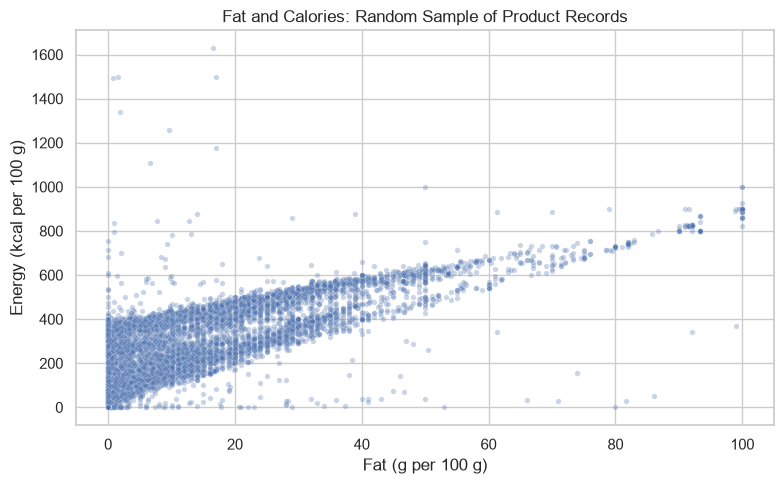

In [22]:
scatter_data = df[
    ["fat_100g", "energy-kcal_100g"]
].dropna()

plot_sample = scatter_data.sample(
    n=min(10000, len(scatter_data)),
    random_state=105,
)

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=plot_sample,
    x="fat_100g",
    y="energy-kcal_100g",
    alpha=0.3,
    s=15,
)

plt.title("Fat and Calories: Random Sample of Product Records")
plt.xlabel("Fat (g per 100 g)")
plt.ylabel("Energy (kcal per 100 g)")
plt.tight_layout()

The scatter plot shows a positive relationship between fat and calories. Products with more fat generally have more calories per 100 g. Calories also vary among products with similar fat content. The plot uses a random sample of up to 10,000 products with both values available.

In [23]:
correlations = df[
    [
        "energy-kcal_100g",
        "fat_100g",
        "sugars_100g",
        "proteins_100g",
    ]
].corr()

display(correlations.round(2))

,energy-kcal_100g,fat_100g,sugars_100g,proteins_100g
energy-kcal_100g,1.00,-0.00,-0.00,-0.00
fat_100g,-0.00,1.00,-0.05,0.12
sugars_100g,-0.00,-0.05,1.00,-0.25
proteins_100g,-0.00,0.12,-0.25,1.00


Sugar and protein have a weak negative correlation (-0.25), meaning products with more sugar tend to have less protein. Fat and protein have a weak positive correlation (0.12), while fat and sugar have almost no relationship (-0.05). Calories show correlations close to zero with the other variables. This is unexpected and will need us to investigate this.

## DATASET QUIRKS

- **Missing information:** There are 931,045 products with an unknown main category and 1,058,300 missing fiber values after cleaning. This limits comparisons involving food categories or fiber. Missing nutrition values were left missing because they do not necessarily mean zero.

- **Uneven country representation:** France has 642,578 records, followed by the United States with 464,902. The results reflect the products included in this dataset, so they should not be treated as equally representative of every country.

- **Unusual nutrition values:** Some nutrient measurements were outside the range of 0–100 grams per 100 grams and were replaced with missing values. The scatter plot also shows unusually high calorie values that may reflect entry or unit errors and need further investigation.

- **Outliers and correlations:** The scatter plot suggests a positive relationship between fat and calories, but the full-data correlation rounds to zero. Extreme calorie values may be affecting this result, so they should be investigated before drawing conclusions.

- **Uneven sugar distribution:** Sugar content is strongly skewed to the right, with many products near zero and fewer products with high sugar content. The mean and median may therefore describe the distribution differently.

- **Products versus consumption:** Each row represents a product record, not how often people buy or eat it. These results cannot directly describe people's diets.

- **Assumptions moving forward:** The analysis treats the nutrition measurements as values per 100 grams. Available values are used for each calculation, which means different comparisons may include different numbers of records. Missing information may also be more common in certain countries or categories.